#question_1

Qus_1-(1)

In [4]:
with open('dataset.csv','r') as f:
    line = f.readlines()
line


['x,fx\n',
 '0.000000,-1.999323\n',
 '0.003003,-1.991155\n',
 '0.006006,-1.981584\n',
 '0.009009,-1.972977\n',
 '0.012012,-1.964272\n',
 '0.015015,-1.954292\n',
 '0.018018,-1.946913\n',
 '0.021021,-1.938282\n',
 '0.024024,-1.928072\n',
 '0.027027,-1.919546\n',
 '0.030030,-1.910048\n',
 '0.033033,-1.902339\n',
 '0.036036,-1.894024\n',
 '0.039039,-1.884796\n',
 '0.042042,-1.875421\n',
 '0.045045,-1.867024\n',
 '0.048048,-1.858226\n',
 '0.051051,-1.848944\n',
 '0.054054,-1.840640\n',
 '0.057057,-1.832350\n',
 '0.060060,-1.823774\n',
 '0.063063,-1.814613\n',
 '0.066066,-1.805854\n',
 '0.069069,-1.797455\n',
 '0.072072,-1.788352\n',
 '0.075075,-1.780138\n',
 '0.078078,-1.771931\n',
 '0.081081,-1.763160\n',
 '0.084084,-1.754801\n',
 '0.087087,-1.746086\n',
 '0.090090,-1.736937\n',
 '0.093093,-1.729163\n',
 '0.096096,-1.720995\n',
 '0.099099,-1.712588\n',
 '0.102102,-1.704400\n',
 '0.105105,-1.696146\n',
 '0.108108,-1.687152\n',
 '0.111111,-1.679398\n',
 '0.114114,-1.670720\n',
 '0.117117,-1.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

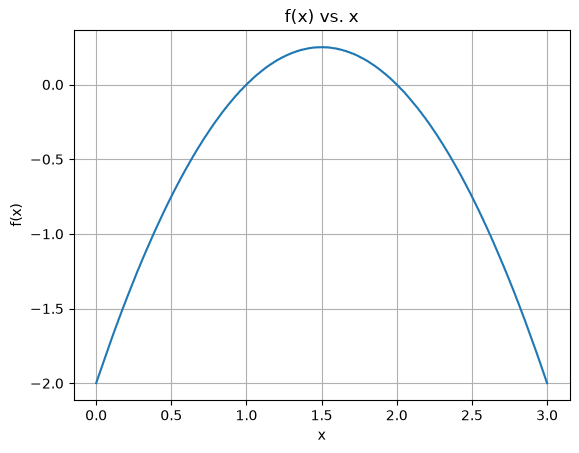

In [6]:
data = np.array([row.strip().split(",") for row in line[1:]], dtype=float)

plt.plot(data[:, 0], data[:, 1])
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("f(x) vs. x")
plt.grid(True)
plt.show()

Qus_1-(2)

In [7]:
def central_difference(data, k):
    """central difference derivatives for k and k=1.
    """

    n = len(data)
    if 2 * k >= n:
        raise ValueError("k is too large for the number of data points")

    i = np.arange(k, n - k)
    x_eval = data[i, 0]

    derivative_k = (data[i + k, 1] - data[i - k, 1]) / (
        data[i + k, 0] - data[i - k, 0]
    )
    derivative_1 = (data[i + 1, 1] - data[i - 1, 1]) / (
        data[i + 1, 0] - data[i - 1, 0]
    )

    return x_eval, derivative_k, derivative_1

Qus_1-(3)

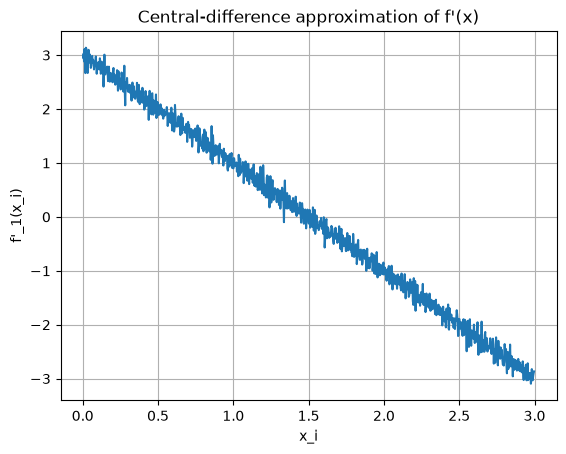

In [8]:
x_eval, _, derivative_1 = central_difference(data, 1)

plt.plot(x_eval, derivative_1)
plt.xlabel(r"x_i")
plt.ylabel(r"f'_1(x_i)")
plt.title(r"Central-difference approximation of f'(x)")
plt.grid(True)
plt.show()

Qus_1-(4)

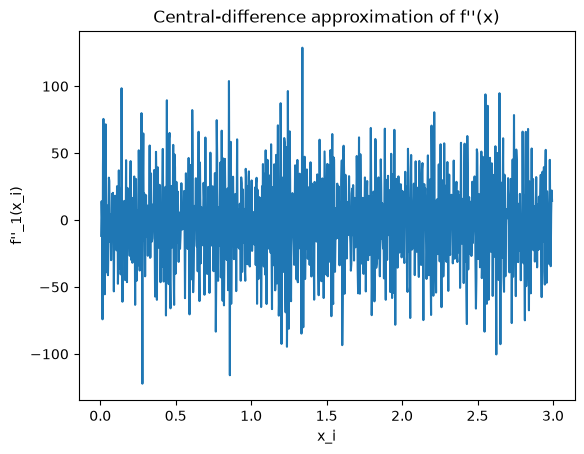

In [9]:
def second_derivative(data, k):
    """Estimate of f'' using central_difference.
    """
    x_first, derivative_k, _ = central_difference(data, k)
    first_derivative_data = np.column_stack((x_first, derivative_k))

    x_second, second_derivative_k, _ = central_difference(first_derivative_data, k)
    return x_second, second_derivative_k


x_second, f_double_prime_1 = second_derivative(data, 1)

plt.plot(x_second, f_double_prime_1)
plt.xlabel(r"x_i")
plt.ylabel(r"f''_1(x_i)")
plt.title(r"Central-difference approximation of f''(x)")
plt.show()

Qus_1-(5)

In [10]:
def relative_derivative_errors(data, k):
    x_first, f_prime_k, f_prime_1 = central_difference(data, k)

    x_second_k, f_double_prime_k = second_derivative(data, k)
    x_second_1, f_double_prime_1 = second_derivative(data, 1)
    x_common, idx_k, idx_1 = np.intersect1d(
        x_second_k, x_second_1, return_indices=True
    )
    x_common, idx_common, idx_first = np.intersect1d(
        x_common, x_first, return_indices=True
    )
    idx_k = idx_k[idx_common]
    idx_1 = idx_1[idx_common]

    def relative_error(estimate, reference):
        numerator = np.abs(estimate - reference)
        denominator = np.abs(reference)
        return np.divide(
            numerator,
            denominator,
            out=np.full_like(numerator, np.nan, dtype=float),
            where=denominator != 0,
        )

    delta_prime = relative_error(f_prime_k[idx_first], f_prime_1[idx_first])
    delta_double_prime = relative_error(
        f_double_prime_k[idx_k], f_double_prime_1[idx_1]
    )

    return delta_prime, delta_double_prime, x_common


delta_prime, delta_double_prime, x_common = relative_derivative_errors(data, 2)
print("Relative errors in first derivative:", delta_prime)
print("Relative errors in second derivative:", delta_double_prime)

Relative errors in first derivative: [7.22237089e-02 6.62480558e-04 1.30543410e-01 7.79151850e-02
 1.61987617e-02 2.91278296e-03 1.06352066e-02 8.43110334e-02
 1.30821410e-02 5.08251357e-02 7.14607247e-03 4.25123582e-02
 3.81360619e-02 1.41589901e-02 3.80860552e-02 1.77576189e-02
 1.93944861e-02 2.63671875e-02 3.22298636e-02 1.51125586e-02
 2.05289600e-02 4.42421290e-02 1.19271999e-02 6.07122008e-03
 2.47745110e-02 4.84493954e-02 1.18182355e-03 5.06210011e-02
 1.84917044e-02 5.21241338e-03 2.91631188e-02 3.78594620e-02
 5.49319322e-03 4.69510711e-02 5.13335976e-02 1.59608739e-02
 4.48814452e-02 2.27496614e-02 6.26989179e-02 2.93753482e-02
 3.75297358e-02 1.03095210e-01 1.31943487e-01 2.71838537e-02
 1.16626066e-01 5.63963627e-02 2.76149045e-02 3.04376738e-02
 1.37826838e-02 8.41647793e-03 2.31578318e-02 2.62932616e-02
 6.16936818e-02 1.14668700e-02 7.68770923e-02 4.94287790e-02
 3.46396546e-02 4.28482199e-02 2.50112230e-02 1.14377037e-02
 1.53566504e-02 6.79084206e-04 5.49996665e-02 2.

Qus_1-(6)

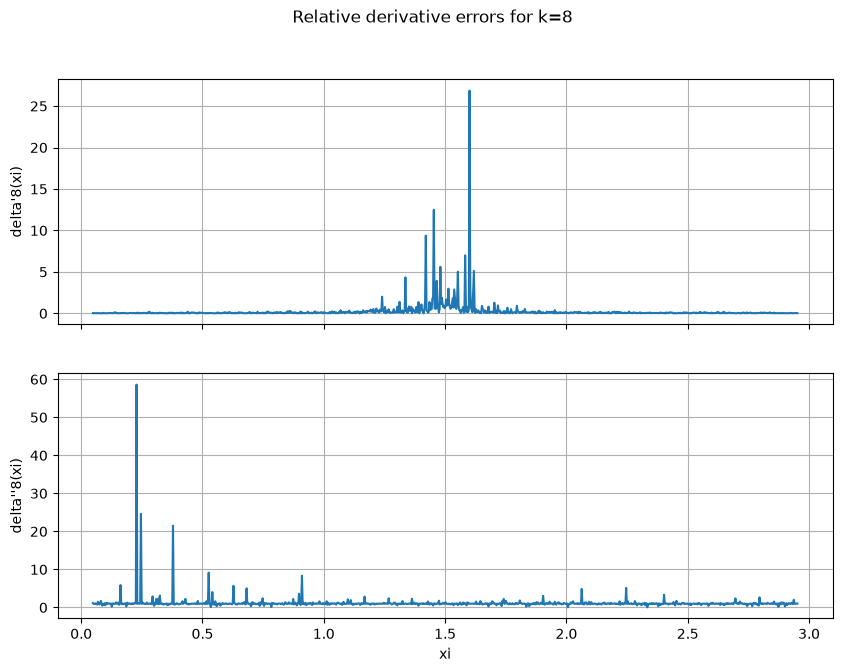

In [11]:
delta_prime_8, delta_double_prime_8, x_common_8 = relative_derivative_errors(data, 8)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(x_common_8, delta_prime_8)
axes[0].set_ylabel(r"delta'8(xi)")
axes[0].grid(True)

axes[1].plot(x_common_8, delta_double_prime_8)
axes[1].set_xlabel(r"xi")
axes[1].set_ylabel(r"delta''8(xi)")
axes[1].grid(True)

fig.suptitle("Relative derivative errors for k=8")
plt.show()

In [21]:
print(f"delta'x spike: xi = {x_common_8}")

delta'x spike: xi = [0.048048 0.051051 0.054054 0.057057 0.06006  0.063063 0.066066 0.069069
 0.072072 0.075075 0.078078 0.081081 0.084084 0.087087 0.09009  0.093093
 0.096096 0.099099 0.102102 0.105105 0.108108 0.111111 0.114114 0.117117
 0.12012  0.123123 0.126126 0.129129 0.132132 0.135135 0.138138 0.141141
 0.144144 0.147147 0.15015  0.153153 0.156156 0.159159 0.162162 0.165165
 0.168168 0.171171 0.174174 0.177177 0.18018  0.183183 0.186186 0.189189
 0.192192 0.195195 0.198198 0.201201 0.204204 0.207207 0.21021  0.213213
 0.216216 0.219219 0.222222 0.225225 0.228228 0.231231 0.234234 0.237237
 0.24024  0.243243 0.246246 0.249249 0.252252 0.255255 0.258258 0.261261
 0.264264 0.267267 0.27027  0.273273 0.276276 0.279279 0.282282 0.285285
 0.288288 0.291291 0.294294 0.297297 0.3003   0.303303 0.306306 0.309309
 0.312312 0.315315 0.318318 0.321321 0.324324 0.327327 0.33033  0.333333
 0.336336 0.339339 0.342342 0.345345 0.348348 0.351351 0.354354 0.357357
 0.36036  0.363363 0.366366 0.3

Qus_1-(7)

In [22]:
def running_average(p, N=1):
    p = np.asarray(p)
    if p.ndim != 1:
        raise ValueError("p must be one-dimensional")
    if not isinstance(N, (int, np.integer)) or N < 1 or N >= len(p):
        raise ValueError("N must be an integer satisfying 1 <= N < len(p)")

    cumulative = np.concatenate(([0], np.cumsum(p)))
    return (cumulative[N + 1:] - cumulative[:-N - 1]) / N
print(running_average(delta_prime_8, 5))

[0.03326132 0.02823582 0.02949441 0.02329565 0.02458845 0.02143346
 0.01616638 0.01443271 0.02212615 0.02061148 0.0258453  0.0284077
 0.02956936 0.03407172 0.0281412  0.02842121 0.01877019 0.02776041
 0.0333635  0.03674596 0.036033   0.04434583 0.04552278 0.03892132
 0.03747851 0.05569036 0.05745779 0.06782212 0.06549883 0.06489066
 0.0630896  0.03803744 0.03583895 0.02521682 0.02543206 0.03241663
 0.02978322 0.03807876 0.04303414 0.0455088  0.04534156 0.03530934
 0.0359625  0.03026883 0.02451698 0.02081245 0.02712048 0.037506
 0.04206531 0.04351679 0.04364378 0.0466999  0.04485173 0.03541668
 0.03064429 0.03966714 0.03799635 0.04284461 0.04951416 0.04724613
 0.05250456 0.04242553 0.04683434 0.04398277 0.03522548 0.04878912
 0.04991909 0.04679006 0.04118842 0.04035837 0.03923443 0.04974779
 0.05117487 0.08701899 0.09214252 0.08387924 0.08262315 0.07127182
 0.06207065 0.03083208 0.02917622 0.02916401 0.03423792 0.02826517
 0.02718894 0.02797279 0.02719478 0.04174545 0.03933683 0.0439905

Qus_1-(8)

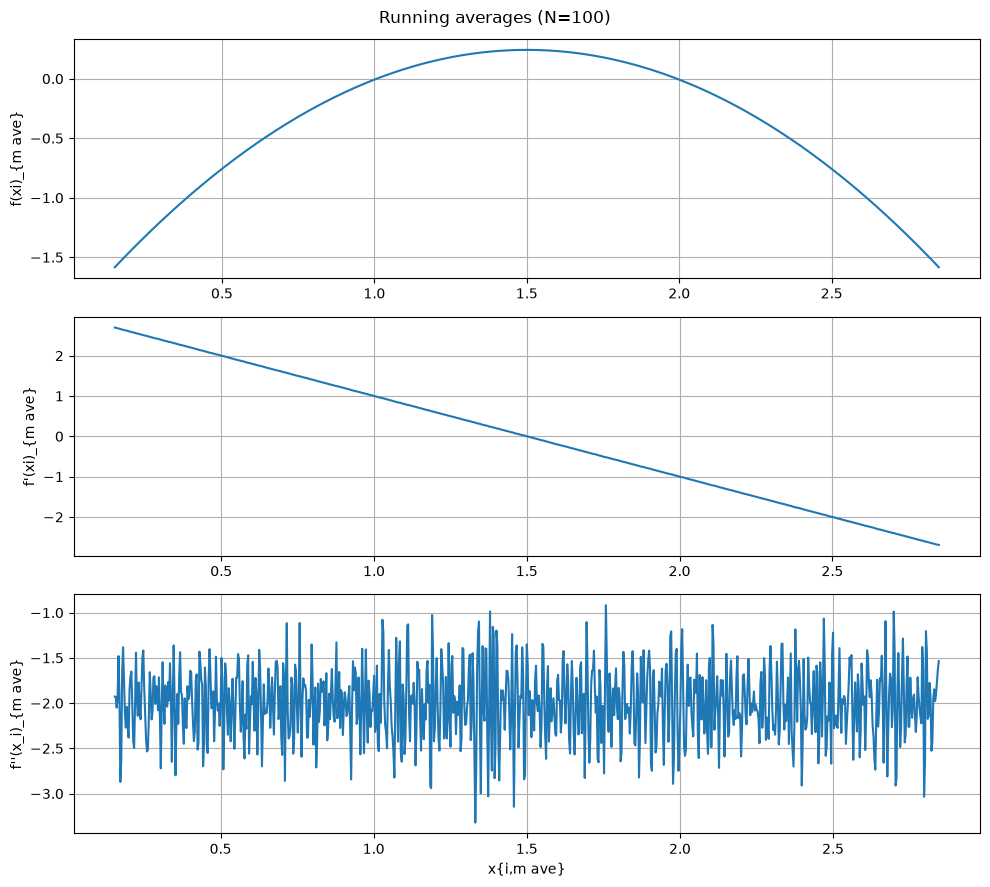

In [23]:
def running_average(p, N=1):
    p = np.array(p)
    cumulative = np.concatenate(([0], np.cumsum(p)))
    return (cumulative[N:] - cumulative[:-N]) / N
N = 100

x_f_ave = running_average(data[:, 0], N)
f_ave = running_average(data[:, 1], N)

x_prime_ave = running_average(x_eval, N)
f_prime_ave = running_average(derivative_1, N)

x_double_prime_ave = running_average(x_second, N)
f_double_prime_ave = running_average(f_double_prime_1, N)

fig, axes = plt.subplots(3, 1, figsize=(10, 9))

axes[0].plot(x_f_ave, f_ave)
axes[0].set_ylabel(r"f(xi)_{m ave}")

axes[1].plot(x_prime_ave, f_prime_ave)
axes[1].set_ylabel(r"f'(xi)_{m ave}")

axes[2].plot(x_double_prime_ave, f_double_prime_ave)
axes[2].set_xlabel(r"x{i,m ave}")
axes[2].set_ylabel(r"f''(x_i)_{m ave}")

for ax in axes:
    ax.grid(True)

fig.suptitle(f"Running averages (N={N})")
fig.tight_layout()
plt.show()

qus_1(9)

from all of the above argument of function and its derivatives my guess function is-
f(x) = -x^2 + Bx + C, (approximate analytic function)
where B and C can be choosen as per the requirement of graph.

Question_2

qus_2(1)